/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/tmp/ipykernel_1648/721009589.py:32: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  tactical_ratings[scouted_player] += (performance_score - tactical_ratings[scouted_player]) / appearances[scouted_player]


Squad depth available: 10

--- Tactical Report: Risk-Taking Strategy ---
Player Performance Ratings: [-0.63 -0.22 -1.16  0.14  0.09 -0.08  0.13 -3.11  0.08  0.11]
Total Match Appearances: [  7   7   5 328  12   9  11   1  38  82]
Average Team Performance Index: 0.0914024956436281


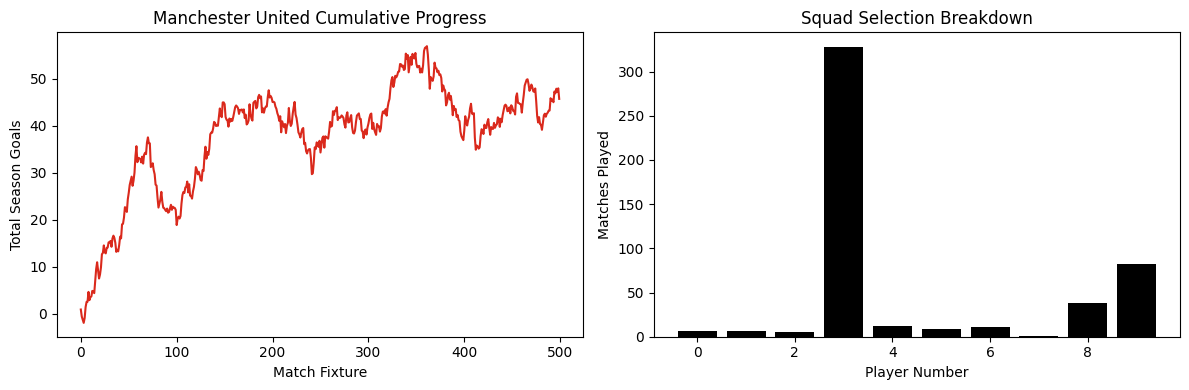


--- Tactical Report: Structured Calculator Strategy ---
Player Performance Ratings: [-0.09 -0.35 -0.16  0.11 -0.33 -0.35 -2.67  0.02 -0.09 -0.09]
Total Match Appearances: [ 64  25  38 106  45  48   1  76  59  38]
Average Team Performance Index: -0.09987108871234918


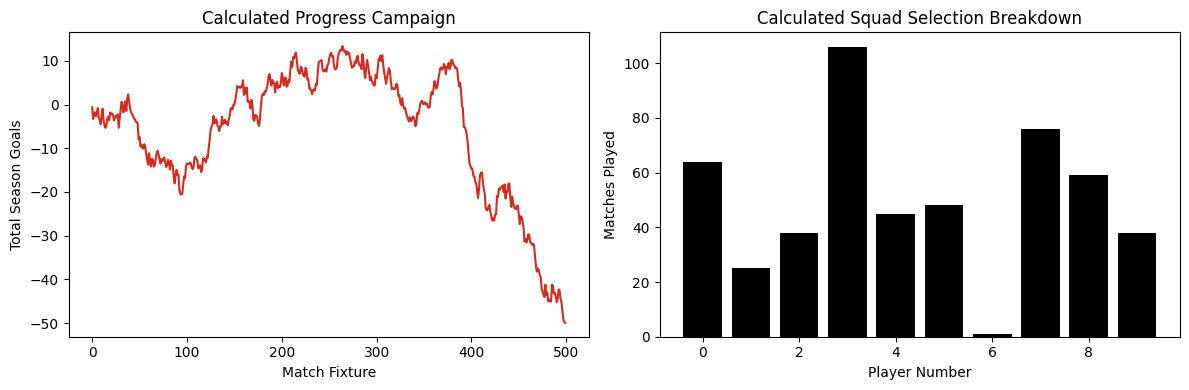

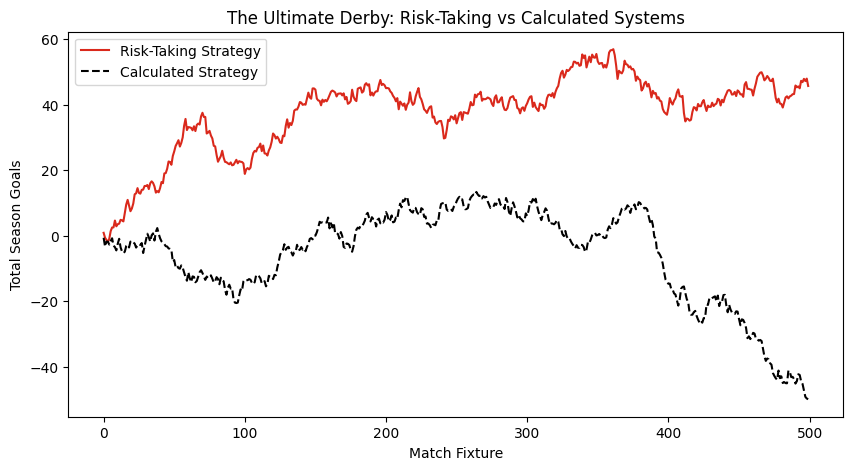

In [2]:
!pip install gym-bandits
import gym
import gym_bandits
import numpy as np
import matplotlib.pyplot as plt

np.bool8 = np.bool_

old_trafford = gym.make("MultiarmedBandits-v0")
the_gaffer = old_trafford.unwrapped
n_squad_players = the_gaffer.action_space.n
match_fixtures = 500

print("Squad depth available:", n_squad_players)

tactical_risk = 0.1
tactical_ratings = np.zeros(n_squad_players)
appearances = np.zeros(n_squad_players)
season_goals = []

for match in range(match_fixtures):
    the_gaffer.reset()

    if np.random.rand() < tactical_risk:
        scouted_player = the_gaffer.action_space.sample()
    else:
        scouted_player = np.argmax(tactical_ratings)

    scout_report, performance_score, full_time, match_stats = the_gaffer.step(scouted_player)

    appearances[scouted_player] += 1
    tactical_ratings[scouted_player] += (performance_score - tactical_ratings[scouted_player]) / appearances[scouted_player]
    season_goals.append(performance_score)

print("\n--- Tactical Report: Risk-Taking Strategy ---")
print("Player Performance Ratings:", np.round(tactical_ratings, 2))
print("Total Match Appearances:", appearances.astype(int))
print("Average Team Performance Index:", np.mean(season_goals))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(season_goals), color='#DA291C')
plt.title("Manchester United Cumulative Progress")
plt.xlabel("Match Fixture")
plt.ylabel("Total Season Goals")

plt.subplot(1, 2, 2)
plt.bar(range(n_squad_players), appearances, color='#000000')
plt.title("Squad Selection Breakdown")
plt.xlabel("Player Number")
plt.ylabel("Matches Played")
plt.tight_layout()
plt.show()

tactical_discipline = 0.5
tactical_ratings_calculated = np.zeros(n_squad_players)
appearances_calculated = np.zeros(n_squad_players)
season_goals_calculated = []

for match in range(match_fixtures):
    the_gaffer.reset()

    selection_fever = np.exp(tactical_ratings_calculated / tactical_discipline)
    selection_probabilities = selection_fever / np.sum(selection_fever)

    scouted_player = np.random.choice(n_squad_players, p=selection_probabilities)

    scout_report, performance_score, full_time, match_stats = the_gaffer.step(scouted_player)

    appearances_calculated[scouted_player] += 1
    tactical_ratings_calculated[scouted_player] += (performance_score - tactical_ratings_calculated[scouted_player]) / appearances_calculated[scouted_player]
    season_goals_calculated.append(performance_score)

print("\n--- Tactical Report: Structured Calculator Strategy ---")
print("Player Performance Ratings:", np.round(tactical_ratings_calculated, 2))
print("Total Match Appearances:", appearances_calculated.astype(int))
print("Average Team Performance Index:", np.mean(season_goals_calculated))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(season_goals_calculated), color='#DA291C')
plt.title("Calculated Progress Campaign")
plt.xlabel("Match Fixture")
plt.ylabel("Total Season Goals")

plt.subplot(1, 2, 2)
plt.bar(range(n_squad_players), appearances_calculated, color='#000000')
plt.title("Calculated Squad Selection Breakdown")
plt.xlabel("Player Number")
plt.ylabel("Matches Played")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(season_goals), label="Risk-Taking Strategy", color='#DA291C')
plt.plot(np.cumsum(season_goals_calculated), label="Calculated Strategy", color='#000000', linestyle='--')
plt.title("The Ultimate Derby: Risk-Taking vs Calculated Systems")
plt.xlabel("Match Fixture")
plt.ylabel("Total Season Goals")
plt.legend()
plt.show()

the_gaffer.close()